# 12 · Recommender systems in the LLM era

Modern recommendation has two stages — **retrieval** (millions → hundreds) and **ranking** — and the LLM toolbox is now central to both:

1. **Sequential recommendation = next-token prediction over item ids.** SASRec (2018) is literally a decoder-only transformer whose vocabulary is the catalog; Meta's HSTU (2024) scales this idea to production. We reuse `TransformerLM` *unchanged*.
2. **Embedding retrieval**: users and items as vectors; the item embeddings learned by the sequential model carry collaborative signal, and **content embeddings** of item text solve cold start.
3. **LLM re-ranking and explanations** at the top of the funnel (tens of candidates), with a local LLM through LangChain.

**Evaluation:** leave-one-out, hit@k and nDCG@k against popularity and content baselines.

**Source:** `llm_edu_suite/recsys.py` (data, SASRec training, embeddings); the LLM stage uses LangChain with `ChatOllama` via `llm_edu_suite.config.get_llm()`.

In [1]:
import os, sys, math, time, random, copy
ROOT = os.path.abspath(".")
while not os.path.isdir(os.path.join(ROOT, "llm_edu_suite")) and os.path.dirname(ROOT) != ROOT:
    ROOT = os.path.dirname(ROOT)                    # climb from notebooks/<topic>/ up to the repo root
sys.path.insert(0, ROOT)                            # so that `import llm_edu_suite` works from any notebook
import numpy as np
import matplotlib.pyplot as plt
import torch, torch.nn as nn, torch.nn.functional as F
from llm_edu_suite.utils import seed_everything, get_device, count_params, human
seed_everything(0)
device = get_device()
print("torch", torch.__version__, "| device", device)

torch 2.14.1+cu130 | device cuda


In [2]:
from llm_edu_suite.recsys import (make_catalog, make_interactions, leave_one_out_split, popularity_ranker, train_sasrec, sasrec_rank,
                             item_embeddings_from_model, content_embeddings, embedding_rank)
from llm_edu_suite.evaluation import evaluate_ranking

catalog = make_catalog(n_items=200, n_clusters=8, seed=0)
sessions = make_interactions(catalog, n_users=1500, min_len=8, max_len=25, stickiness=0.8, seed=0)
train_sessions, test = leave_one_out_split(sessions)
print(f"{catalog.n_items} items, {len(sessions)} users, avg session length {sum(map(len, sessions))/len(sessions):.1f}")
print("item 1:", catalog.titles[0], "—", catalog.descriptions[0])
print("a session (item ids):", sessions[0])

200 items, 1500 users, avg session length 16.7
item 1: Clever Secret 0 — A clever sci-fi secret about journey and voyage.
a session (item ids): [120, 85, 165, 134, 96, 48, 21, 80, 64, 192, 61, 5, 48]


## 1. Baselines
Always beat popularity first. A random ranker is expected to hit 10/200 = 5 % on average; the measured value below (0.032) is one noisy sample of that.

In [3]:
MAXLEN = 32
pop_rank = popularity_ranker(train_sessions, catalog.n_items)
def eval_ranker(rank_fn, name, k=10):
    queries = [(rank_fn(hist, k), {target}) for hist, target in test]
    m = evaluate_ranking(queries, ks=(1, 5, 10))
    print(f"{name:22s} hit@1 {m['hit@1']:.3f}  hit@5 {m['hit@5']:.3f}  hit@10 {m['hit@10']:.3f}  ndcg@10 {m['ndcg@10']:.3f}  mrr {m['mrr']:.3f}")
    return m

results = {}
results["random"] = eval_ranker(lambda h, k: random.sample([i for i in range(1, catalog.n_items + 1) if i not in h], k), "random")
results["popularity"] = eval_ranker(pop_rank, "popularity")
E_content = content_embeddings(catalog)
results["content (cold-start)"] = eval_ranker(lambda h, k: embedding_rank(E_content, h, k), "content embeddings")

random                 hit@1 0.004  hit@5 0.015  hit@10 0.032  ndcg@10 0.015  mrr 0.010
popularity             hit@1 0.020  hit@5 0.056  hit@10 0.097  ndcg@10 0.051  mrr 0.037
content embeddings     hit@1 0.009  hit@5 0.043  hit@10 0.069  ndcg@10 0.034  mrr 0.023


## 2. Sequential recommender = a language model over items
`vocab_size = n_items + 1` (0 = padding). Input: items `[:-1]`, target: items `[1:]`, padding ignored. That is all; the model, loss and optimizer are the ones from the pretraining notebook.

In [4]:
from llm_edu_suite.model import ModelConfig, TransformerLM
seed_everything(0)
rec = TransformerLM(ModelConfig(vocab_size=catalog.n_items + 1, max_seq_len=MAXLEN + 1, d_model=64, n_layers=2, n_heads=4, n_kv_heads=2, dropout=0.1))
print(f"SASRec-style model: {human(rec.num_params())} params")
losses = train_sasrec(rec, train_sessions, max_len=MAXLEN, steps=600, batch_size=64, lr=2e-3, device=device, log_every=150)
results["SASRec (transformer)"] = eval_ranker(lambda h, k: sasrec_rank(rec, h, k, max_len=MAXLEN, device=device), "SASRec (transformer)")

SASRec-style model: 105.34K params


sasrec step    0  loss 5.259


sasrec step  150  loss 3.903


sasrec step  300  loss 3.778


sasrec step  450  loss 3.718


sasrec step  599  loss 3.446


SASRec (transformer)   hit@1 0.039  hit@5 0.137  hit@10 0.210  ndcg@10 0.114  mrr 0.084


## 3. Embedding retrieval from the learned model
The input embedding table of the sequential model is an item-vector space learned from co-occurrence (collaborative filtering). A user vector = recency-weighted mean of their items; retrieval = cosine top-k. This is the "two-tower-ish" retrieval stage you would serve from an ANN index.

In [5]:
E_collab = item_embeddings_from_model(rec)
results["collab embeddings"] = eval_ranker(lambda h, k: embedding_rank(E_collab, h, k), "collab embeddings")

# Look at an item's nearest neighbours in the learned space. Do they share its hidden taste cluster?
i = 5
sims = E_collab @ E_collab[i]; sims[0] = -1; sims[i] = -1
nn_items = np.argsort(-sims)[:5]
print(f"neighbours of '{catalog.titles[i-1]}' (cluster {catalog.item_cluster[i-1]}):")
for j in nn_items:
    print(f"   {catalog.titles[j-1]:28s} cluster {catalog.item_cluster[j-1]}  sim {sims[j]:.2f}")

collab embeddings      hit@1 0.039  hit@5 0.124  hit@10 0.207  ndcg@10 0.108  mrr 0.078
neighbours of 'Fast-Paced Heist 4' (cluster 4):
   Funny Voyage 12              cluster 4  sim 0.64
   Classic Rivalry 20           cluster 4  sim 0.50
   Dark Mystery 28              cluster 4  sim 0.49
   Emotional Voyage 36          cluster 4  sim 0.40
   Clever Journey 76            cluster 4  sim 0.40


## 4. LLM re-ranking and explanations

The two-stage pattern used in production: a cheap model retrieves a short list (here SASRec's top 20), and an LLM re-orders it by reading the user's history and the item descriptions, then explains the top pick. The LLM is far too slow to score 200 items for every user, but 20 candidates fit in one prompt. It can bring knowledge the sequential model lacks (what a description *means*, cold-start items with no interactions), and it can write explanations.

We call the course's local model (`qwen2.5:3b` through Ollama, via `get_llm()`) with LangChain. The re-ranking is a **structured output** call: a Pydantic model with a list of candidate numbers, so we never parse free text. Bound every list in an output schema (`max_length`) and cap the output tokens: we learned this the hard way, when an unbounded list made the model generate numbers until its context was full. Candidates the reply leaves out keep their SASRec order at the end, and duplicated or out-of-range numbers are dropped.

Is it worth it? Only the offline metric can say, so we evaluate on 50 test users (one LLM call each), against SASRec alone and against a trivial **genre-match** re-ranker (sort the candidates by how many of the user's last 5 items share their genre, a signal the LLM can also read from the descriptions).

In [6]:
from pydantic import BaseModel, Field
from langchain_core.prompts import ChatPromptTemplate
from llm_edu_suite.config import setup, get_llm
setup(project="llm-edu-suite-12-recsys")
llm = get_llm(num_predict=200)           # a hard cap on output tokens: a ranking of 20 numbers needs about 80

class Ranking(BaseModel):
    # max_length becomes "maxItems" in the JSON Schema. Without it, constrained decoding lets a small model keep
    # emitting numbers until the context is full, and one call takes minutes instead of seconds.
    order: list[int] = Field(description="the candidate numbers, from most to least relevant for this user", max_length=20)

RERANK = ChatPromptTemplate.from_messages([
    ("system", "You are a recommendation assistant for a streaming service. Given what the user watched recently "
               "and a numbered list of candidate titles, rank ALL candidates from most to least likely to be watched next."),
    ("human", "Recently watched (oldest first):\n{history}\n\nCandidates:\n{candidates}\n\nReturn the candidate numbers in ranked order."),
])
rerank_chain = RERANK | llm.with_structured_output(Ranking)

def describe(i):
    return f"{catalog.titles[i - 1]}: {catalog.descriptions[i - 1]}"

def rerank_inputs(hist, cands, max_history=5):
    return {"history": "\n".join(f"- {describe(i)}" for i in hist[-max_history:]),
            "candidates": "\n".join(f"{n}. {describe(i)}" for n, i in enumerate(cands, start=1))}

def apply_order(order, cands):
    """Map 1-based candidate numbers back to item ids; ignore invalid or repeated numbers, append the rest in SASRec order."""
    ranked = []
    for n in order:
        if 1 <= n <= len(cands) and cands[n - 1] not in ranked:
            ranked.append(cands[n - 1])
    return ranked + [c for c in cands if c not in ranked]

def genre_rerank(hist, cands):
    recent = [catalog.genres[i - 1] for i in hist[-5:]]
    return sorted(cands, key=lambda c: -recent.count(catalog.genres[c - 1]))     # a stable sort keeps SASRec order within ties

EXPLAIN = ChatPromptTemplate.from_template(
    "The user recently watched: {history}. In one sentence, explain why they might enjoy '{item}'.") | llm

hist, target = test[0]
cands = sasrec_rank(rec, hist, 20, max_len=MAXLEN, device=device)
ranking = rerank_chain.invoke(rerank_inputs(hist, cands))
reranked = apply_order(ranking.order, cands)
print("history (last 3):", [describe(i) for i in hist[-3:]])
print("SASRec top 5    :", cands[:5])
print("LLM order (raw) :", ranking.order)
print("LLM top 5       :", reranked[:5])
print("explanation     :", EXPLAIN.invoke({"history": ", ".join(catalog.titles[i - 1] for i in hist[-3:]), "item": describe(reranked[0])}).content)

provider        : ollama
chat_model      : qwen2.5:3b
embedding_model : nomic-embed-text
ollama_running  : True
langsmith       : on (project: llm-edu-suite-12-recsys)


history (last 3): ['Emotional Mystery 191: A emotional horror mystery about mystery and voyage.', 'Emotional Journey 60: A emotional comedy journey about kingdom and kingdom.', 'Fast-Paced Heist 4: A fast-paced comedy heist about heist and rivalry.']
SASRec top 5    : [16, 8, 32, 24, 160]
LLM order (raw) : [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20]
LLM top 5       : [16, 8, 32, 24, 160]


explanation     : Given the user's recent interest in fast-paced and mysterious content, they might enjoy "Fast-Paced Family 15" as it combines those elements with a family-oriented premise, promising a thrilling and suspenseful experience.


In [7]:
N_USERS = 50
sub_test = test[:N_USERS]
cand_lists = [sasrec_rank(rec, h, 20, max_len=MAXLEN, device=device) for h, _ in sub_test]
t0 = time.time()
replies = rerank_chain.batch([rerank_inputs(h, c) for (h, _), c in zip(sub_test, cand_lists)],
                             config={"max_concurrency": 4}, return_exceptions=True)
llm_seconds = time.time() - t0
failed = sum(isinstance(r, Exception) or r is None for r in replies)
llm_lists = [c if isinstance(r, Exception) or r is None else apply_order(r.order, c) for r, c in zip(replies, cand_lists)]
complete = sum(not isinstance(r, Exception) and r is not None and sorted(set(r.order)) == list(range(1, 21)) for r in replies)

rerank_results = {
    "SASRec": evaluate_ranking([(c[:10], {t}) for c, (_, t) in zip(cand_lists, sub_test)], ks=(1, 5, 10)),
    "+ genre-match rerank": evaluate_ranking([(genre_rerank(h, c)[:10], {t}) for c, (h, t) in zip(cand_lists, sub_test)], ks=(1, 5, 10)),
    "+ LLM rerank": evaluate_ranking([(l[:10], {t}) for l, (_, t) in zip(llm_lists, sub_test)], ks=(1, 5, 10)),
}
recall20 = np.mean([t in c for c, (_, t) in zip(cand_lists, sub_test)])
print(f"{N_USERS} users: LLM re-ranking took {llm_seconds:.0f}s ({1000 * llm_seconds / N_USERS:.0f} ms/user), "
      f"{failed} failed calls, {complete} replies ranked all 20 candidates exactly once")
print(f"the target is in SASRec's top 20 for {recall20:.0%} of these users: that is the ceiling for any re-ranker\n")
for name, m in rerank_results.items():
    print(f"  {name:22s} hit@1 {m['hit@1']:.2f}  hit@5 {m['hit@5']:.2f}  hit@10 {m['hit@10']:.2f}  ndcg@10 {m['ndcg@10']:.3f}")

50 users: LLM re-ranking took 70s (1405 ms/user), 0 failed calls, 38 replies ranked all 20 candidates exactly once
the target is in SASRec's top 20 for 32% of these users: that is the ceiling for any re-ranker

  SASRec                 hit@1 0.00  hit@5 0.10  hit@10 0.20  ndcg@10 0.088
  + genre-match rerank   hit@1 0.00  hit@5 0.06  hit@10 0.20  ndcg@10 0.079
  + LLM rerank           hit@1 0.02  hit@5 0.08  hit@10 0.16  ndcg@10 0.077


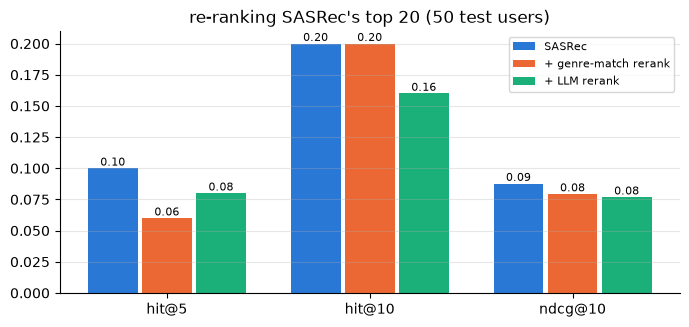

In [8]:
fig, ax = plt.subplots(figsize=(8, 3.4)); names_r = list(rerank_results); ks_r = ["hit@5", "hit@10", "ndcg@10"]
xs = np.arange(len(ks_r)); w = 0.8 / len(names_r)
for i, (n, col) in enumerate(zip(names_r, ["#2a78d6", "#eb6834", "#1baf7a"])):
    bars = ax.bar(xs + (i - 1) * w, [rerank_results[n][k] for k in ks_r], w * 0.92, color=col, label=n)
    ax.bar_label(bars, fmt="%.2f", fontsize=8)
ax.set_xticks(xs); ax.set_xticklabels(ks_r); ax.legend(fontsize=8); ax.set_title(f"re-ranking SASRec's top 20 ({N_USERS} test users)")
ax.grid(axis="y", alpha=.3); ax.spines[["top", "right"]].set_visible(False); plt.show()

**What the numbers say.** On these 50 users the LLM re-ranker makes things **worse**: hit@10 drops from 0.20 (SASRec alone) to 0.16 and nDCG@10 from 0.088 to 0.077; the one gain is a single extra hit at rank 1 (hit@1 0.00 to 0.02). The genre-match heuristic does not help either (hit@10 unchanged at 0.20, nDCG@10 0.079). It also cost about 70 s for 50 users (≈1.4 s per user on the GPU; several times more when the GPU is shared), against milliseconds for SASRec.

Why? The re-ranker can only reorder what the first stage found, and the target is in SASRec's top 20 for just 32% of these users, so the ceiling is low. Inside that list, SASRec's order already encodes what decides the next item in this synthetic data: the user's hidden taste clusters *and* the within-cluster popularity, learned from 1,500 users' sequences. The LLM sees only titles and one-line descriptions; genre is the only real signal in them, and the genre heuristic shows that genre alone adds nothing on top of SASRec. The 3B model also follows the format imperfectly: some replies (12 of 50 in this run) did not rank each of the 20 candidates exactly once (missing or repeated numbers, which `apply_order` repairs), and in the example above it simply returned the input order. With 50 users, the difference between 10 and 8 hits is not statistically solid, but there is no sign of a gain (and in earlier runs the drop was larger).

This is the realistic lesson: an LLM re-ranker earns its latency only where the first stage is weak and the text carries information the interaction data does not: cold-start items, rich descriptions, explicit user requests ("something lighter than last night"). Measure it offline first, exactly like this, before paying for it in production. The explanation cell is the part that works well with a small model: it writes a fluent, plausible reason, which is valuable for the interface even when it does not change the ranking.

## 5. Evaluation summary

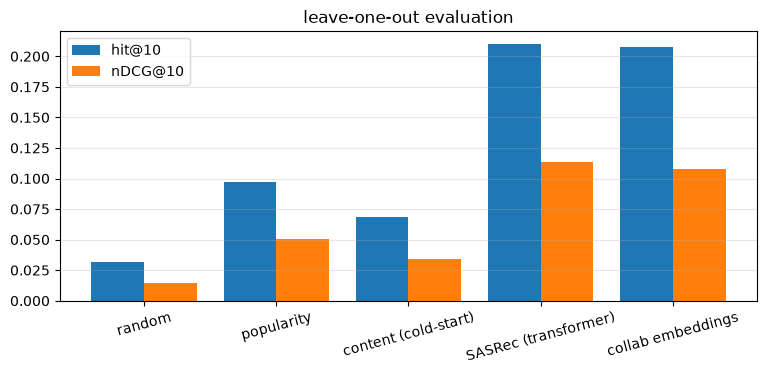

In [9]:
import matplotlib.pyplot as plt
names = list(results); h10 = [results[n]["hit@10"] for n in names]; nd = [results[n]["ndcg@10"] for n in names]
fig, ax = plt.subplots(figsize=(9, 3.5)); xs = np.arange(len(names))
ax.bar(xs - 0.2, h10, 0.4, label="hit@10"); ax.bar(xs + 0.2, nd, 0.4, label="nDCG@10")
ax.set_xticks(xs); ax.set_xticklabels(names, rotation=15); ax.legend(); ax.set_title("leave-one-out evaluation"); ax.grid(axis="y", alpha=.3); plt.show()

**Takeaways**
- The sequential transformer should clearly beat popularity and content baselines: it learns both taste clusters and within-cluster popularity from sequences alone.
- Content embeddings are weaker but work for items with **zero** interactions — in production you combine both (hybrid retrieval, exactly like RAG's dense + BM25).
- An LLM re-ranker is a hypothesis to test, not an upgrade: here, with a 3B model reading short synthetic descriptions, it lowered hit@10 from 0.20 to 0.16 on 50 users. LLMs earn their place at the top of the funnel for cold start, rich text and explanations.
- Offline metrics (hit@k, nDCG) are necessary but not sufficient: the real test is an **A/B experiment** on engagement/retention; offline-online gaps are common (popularity bias, feedback loops).
- Reading: SASRec (Kang & McAuley 2018), HSTU / "Actions speak louder than words" (Meta 2024), TIGER (semantic ids, Google 2023), LLM-Rec surveys.

**Next:** `13_modern_llm_applications.ipynb`.